# Exploratory Data Analysis: Retail Customer Sales
**Data Analyst Training Program, Mini Project 1**  
**Author:** Harshit Negi  |  **Roll No:** 2026m01410006

**Goal:** audit, clean, profile and summarise `retail_customer_sales_dataset.csv` (7,084 rows, 24 columns, 2023 to 2024, India) before any further analysis.

**Contents:** 1. Setup and first look · 2. Data quality audit · 3. Data cleaning · 4. Descriptive statistics and univariate analysis · 5. Outlier detection · 6. Feature engineering and grouped business questions · 7. Key findings

## 1. Setup and first look

In [1]:
import re, warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format
os.makedirs("figs", exist_ok=True)

DATA_PATH = "retail_customer_sales_dataset.csv"   # original, untouched data file
raw = pd.read_csv(DATA_PATH)
df = raw.copy()          # 'raw' is never modified, so we can always compare before vs after
print("Shape:", raw.shape)
raw.head()

Shape: (7084, 24)


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.00,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.00,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.00,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.00,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.00,Female,"95,727.49",north,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No


In [2]:
raw.tail()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7079,TXN201768,CUST10870,2024-10-22,2024-10-27,34.00,Male,"79,446.58",East,Odisha,Bhubaneswar,Corporate,Electronics,Laptop Stand,1,"5,395.38",0.09,"4,909.80","3,273.47","1,636.33",Net Banking,Express,2.00,Low,Yes
7080,TXN201737,CUST10314,2024-10-05,2024-10-14,50.00,Male,"21,796.92",East,West Bengal,Durgapur,Home Office,Clothing,Formal Shirt,3,"1,603.82",0.02,"4,715.23","2,923.68","1,791.55",Credit Card,Standard,4.00,High,No
7081,TXN203240,CUST10859,2024-06-04,2024-06-15,42.00,Male,"60,621.27",West,Gujarat,Surat,Consumer,Electronics,Laptop Stand,1,"11,519.59",0.22,"8,985.28","5,360.01","3,625.27",UPI,Standard,2.00,Medium,No
7082,TXN205305,CUST10829,2024-03-31,2024-04-08,32.00,Female,"42,178.47",South,Kerala,Kozhikode,Consumer,Clothing,Running Shoes,3,980.67,0.21,"2,324.19","1,812.17",512.02,UPI,Standard,4.00,High,No
7083,TXN204737,CUST10847,2024-10-18,2024-10-26,63.00,Male,"44,113.29",South,Kerala,Kozhikode,Consumer,Clothing,Denim Jacket,2,"3,727.59",0.30,"5,218.63","3,932.52","1,286.11",Debit Card,Standard,4.00,High,No


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   object 
 1   Customer_ID         7084 non-null   object 
 2   Order_Date          7084 non-null   object 
 3   Delivery_Date       6978 non-null   object 
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   object 
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   object 
 8   State               7084 non-null   object 
 9   City                7084 non-null   object 
 10  Customer_Segment    7084 non-null   object 
 11  Product_Category    7084 non-null   object 
 12  Product             7084 non-null   object 
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount            7013 non-null   float64
 16  Sales 

**First impressions.** 24 columns: IDs, two date columns stored as plain text (`object`), demographics, geography, product and money fields, and a few survey-style fields. Dates being text already tells us they need parsing.

## 2. Data quality audit

### 2.1 Missing values

In [4]:
miss = pd.DataFrame({"missing_count": raw.isna().sum(),
                     "missing_pct": raw.isna().mean() * 100})
miss = miss[miss.missing_count > 0].sort_values("missing_count", ascending=False)
miss

,missing_count,missing_pct
Customer_Rating,428,6.04
Income,253,3.57
Satisfaction_Level,179,2.53
Age,142,2.00
Delivery_Date,106,1.50
Discount,71,1.00


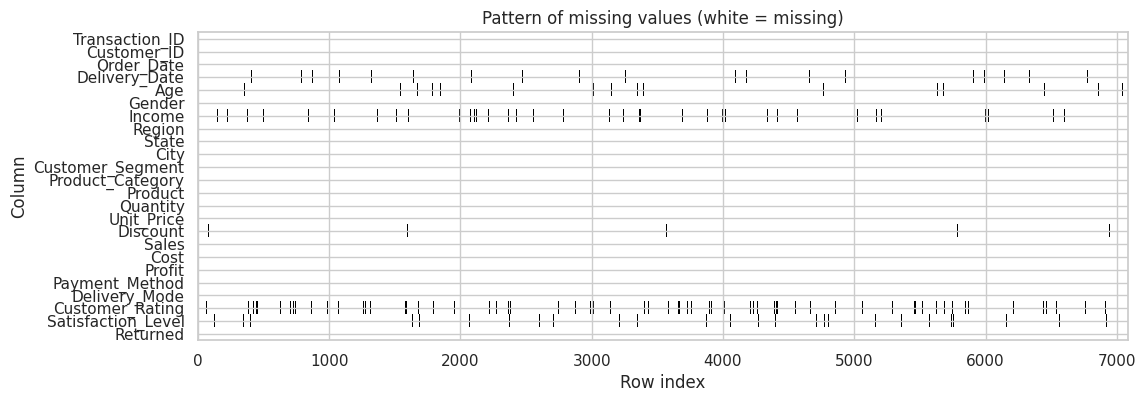

In [5]:
plt.figure(figsize=(12, 4))
plt.imshow(raw.isna().T, aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1)
plt.yticks(range(len(raw.columns)), raw.columns)
plt.xlabel("Row index")
plt.ylabel("Column")
plt.title("Pattern of missing values (white = missing)")
plt.savefig("figs/missing_matrix.png", dpi=130, bbox_inches="tight")
plt.show()

**Observation.** Six columns have gaps: `Customer_Rating` (6.0%), `Income` (3.6%), `Satisfaction_Level` (2.5%), `Age` (2.0%), `Delivery_Date` (1.5%) and `Discount` (1.0%). The gaps are scattered rather than clustered in blocks, which suggests random omissions rather than a systematic failure.

### 2.2 Duplicates

In [6]:
print("Fully identical duplicate rows:", raw.duplicated().sum())
print("Repeated Transaction_IDs      :", raw.Transaction_ID.duplicated().sum())

Fully identical duplicate rows: 61
Repeated Transaction_IDs      : 84


There are **more repeated IDs (84) than identical rows (61)**. Let us see what the extra 23 look like.

In [7]:
only_id_dup = raw[raw.Transaction_ID.duplicated(keep=False) & ~raw.duplicated(keep=False)]
only_id_dup.sort_values("Transaction_ID")[["Transaction_ID","Order_Date","Delivery_Date","Gender","Region","Sales"]].head(8)

,Transaction_ID,Order_Date,Delivery_Date,Gender,Region,Sales
1227,TXN200162,22/07/2024,26/07/2024,Female,South,"3,938.61"
1386,TXN200162,2024-07-22,2024-07-26,Female,South,"3,938.61"
3392,TXN200221,2023-06-23,2023-06-29,female,West,"2,468.85"
6761,TXN200221,2023-06-23,2023-06-29,Female,West,"2,468.85"
3719,TXN200275,30/06/2024,03/07/2024,Male,NORTH,"10,789.70"
2682,TXN200275,30-Jun-2024,03-Jul-2024,Male,North,"10,789.70"
1713,TXN200750,2024-02-11,2024-02-15,female,Sth,"5,317.76"
2679,TXN200750,2024-02-11,2024-02-15,Female,South,"5,317.76"


**Insight.** These rows are the *same transaction* written twice, with only the **formatting** changed (a different date style, `female` vs `Female`, `NORTH` vs `North`). They are hidden duplicates. We will therefore remove duplicates **after** standardising text and dates, not before.

### 2.3 Inconsistent categories

In [8]:
print(raw.Gender.value_counts(), "\n")
print(raw.Region.value_counts())

Gender
Female    3585
Male      3232
female      53
FEMALE      53
male        46
MALE        44
M           38
F           33
Name: count, dtype: int64 

Region
West     1783
East     1754
South    1741
North    1647
east       30
south      24
north      21
Sth        20
WEST       19
Nort       17
west       15
NORTH      13
Name: count, dtype: int64


`Gender` has 8 spellings for 2 values (`M`, `F`, `male`, `FEMALE` ...). `Region` has 12 labels for 4 regions (`Nort`, `Sth`, `north`, `WEST` ...). Other categorical columns:

In [9]:
for c in ["Customer_Segment","Product_Category","Payment_Method","Delivery_Mode","Satisfaction_Level","Returned"]:
    print(c, raw[c].unique().tolist())

Customer_Segment ['Consumer', 'Home Office', 'Corporate']
Product_Category ['Grocery', 'Electronics', 'Clothing', 'Furniture', 'Office Supplies']
Payment_Method ['Debit Card', 'Credit Card', 'UPI', 'Cash on Delivery', 'Net Banking']
Delivery_Mode ['Standard', 'Express', 'Same-Day']
Satisfaction_Level ['Low', 'High', 'Medium', nan]
Returned ['No', 'Yes']


### 2.4 Impossible or out-of-range values

In [10]:
bad_age  = raw[(raw.Age < 0) | (raw.Age > 100)]
bad_disc = raw[(raw.Discount < 0) | (raw.Discount > 0.5)]
bad_inc  = raw[raw.Income > 500_000]
print("Impossible ages    :", bad_age.Age.tolist())
print("Invalid discounts  :", bad_disc.Discount.tolist(), "(valid range is 0 to 0.5)")
print("Income > 500,000   :", len(bad_inc), "rows, max =", f"{raw.Income.max():,.0f}")
print("Quantity range     :", raw.Quantity.min(), "to", raw.Quantity.max())
print("Rating range       :", raw.Customer_Rating.min(), "to", raw.Customer_Rating.max())

Impossible ages    : [-5.0, 180.0, 999.0, -12.0, 150.0, -1.0]
Invalid discounts  : [-0.2, 2.0, 1.1, 1.5, -0.1, 1.2] (valid range is 0 to 0.5)
Income > 500,000   : 6 rows, max = 1,750,890
Quantity range     : 1 to 10
Rating range       : 1.0 to 5.0


### 2.5 Date problems

In [11]:
def date_pattern(s):
    return s.dropna().str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]{3}", "Mon", regex=True)

print(date_pattern(raw.Order_Date).value_counts(), "\n")
print(date_pattern(raw.Delivery_Date).value_counts())

Order_Date
9999-99-99     6601
99-Mon-9999     161
99/99/9999      161
99-99-9999      161
Name: count, dtype: int64 

Delivery_Date
9999-99-99     6509
99-Mon-9999     158
99/99/9999      156
99-99-9999      155
Name: count, dtype: int64


Four date styles are mixed: `2023-12-19`, `19/12/2023`, `12-19-2023`, `19-Dec-2023`. The two all-numeric styles can be ambiguous (is `03/04/2023` 3 April or 4 March?). Instead of guessing, we check which part ever exceeds 12:

In [12]:
for col in ["Order_Date", "Delivery_Date"]:
    s = raw[col].dropna()
    for name, pat in [("slash  dd/mm/yyyy ?", r"^\d\d/\d\d/\d{4}$"), ("dash   ??-??-yyyy", r"^\d\d-\d\d-\d{4}$")]:
        m = s[s.str.match(pat)]
        first, second = m.str[:2].astype(int), m.str[3:5].astype(int)
        print(f"{col:14s} {name:20s} first part >12: {(first>12).sum():3d} | second part >12: {(second>12).sum():3d}")

Order_Date     slash  dd/mm/yyyy ?  first part >12:  92 | second part >12:   0
Order_Date     dash   ??-??-yyyy    first part >12:   0 | second part >12:  99
Delivery_Date  slash  dd/mm/yyyy ?  first part >12:  96 | second part >12:   0
Delivery_Date  dash   ??-??-yyyy    first part >12:   0 | second part >12:  88


**Decision rule (evidence-based).** In slash dates only the *first* part ever exceeds 12, so slash = **DD/MM/YYYY**. In dash-numeric dates only the *second* part ever exceeds 12, so dash = **MM-DD-YYYY**. Applying one rule to both would silently corrupt ~320 dates.

### 2.6 Does the data obey its own business rules?

In [13]:
implied_disc = 1 - raw.Sales / (raw.Quantity * raw.Unit_Price)
print("Rows where Profit != Sales - Cost  :", ((raw.Profit - (raw.Sales - raw.Cost)).abs() > 0.02).sum())
print("Rows where stored Discount disagrees with Sales/(Qty x Price):",
      ((implied_disc - raw.Discount).abs() > 0.02).sum())
raw.loc[(implied_disc - raw.Discount).abs() > 0.02, ["Quantity","Unit_Price","Discount","Sales"]].assign(implied_discount=implied_disc)

Rows where Profit != Sales - Cost  : 0
Rows where stored Discount disagrees with Sales/(Qty x Price): 6


,Quantity,Unit_Price,Discount,Sales,implied_discount
1196,3,"2,084.63",-0.20,"4,252.65",0.32
2624,5,"12,394.56",2.00,"55,155.79",0.11
3165,4,977.82,1.10,"3,598.38",0.08
4174,4,"9,160.38",1.50,"33,343.78",0.09
5410,3,324.04,-0.10,505.50,0.48
6693,5,"1,052.47",1.20,"5,209.73",0.01


**Key discovery.** `Profit = Sales - Cost` holds exactly, and `Sales = Quantity x Unit_Price x (1 - Discount)`. The only rows where Discount disagrees are exactly the 6 invalid discounts. That means any Discount that is invalid **or missing** can be recovered exactly from the other columns rather than guessed.

### Audit summary
| Issue | Count |
|---|---|
| Missing: Customer_Rating / Income / Satisfaction / Age / Delivery_Date / Discount | 428 / 253 / 179 / 142 / 106 / 71 |
| Identical duplicate rows | 61 (plus 23 more hidden by formatting) |
| Gender spellings (expected 2) | 8 |
| Region labels (expected 4) | 12 |
| Impossible Age | 6 |
| Invalid Discount | 6 |
| Income > 500,000 | 6 |
| Date formats mixed | 4 styles |

## 3. Data cleaning

Every step keeps a **flag column** so the original problem is traceable.

### 3.1 Standardise categories
**Why mapping instead of `.title()`?** `M`, `F`, `Nort` and `Sth` would survive `.title()`. An explicit mapping handles them.

In [14]:
gender_map = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}
region_map = {"north": "North", "nort": "North", "south": "South", "sth": "South",
              "east": "East", "west": "West"}
df["Gender"] = df.Gender.str.strip().str.lower().map(gender_map)
df["Region"] = df.Region.str.strip().str.lower().map(region_map)
print(df.Gender.value_counts(dropna=False).to_dict())
print(df.Region.value_counts(dropna=False).to_dict())

{'Female': 3724, 'Male': 3360}
{'West': 1817, 'South': 1785, 'East': 1784, 'North': 1698}


### 3.2 Parse dates
Using the rule established in 2.5. Anything that fails parsing becomes `NaT` (not guessed).

In [15]:
def parse_date(s):
    if pd.isna(s):
        return pd.NaT
    s = s.strip()
    if re.match(r"^\d{4}-\d\d-\d\d$", s):   fmt = "%Y-%m-%d"
    elif "/" in s:                              fmt = "%d/%m/%Y"
    elif re.match(r"^\d\d-\d\d-\d{4}$", s): fmt = "%m-%d-%Y"
    else:                                       fmt = "%d-%b-%Y"
    return pd.to_datetime(s, format=fmt, errors="coerce")

df["Order_Date"]    = df.Order_Date.map(parse_date)
df["Delivery_Date"] = df.Delivery_Date.map(parse_date)
print(df[["Order_Date","Delivery_Date"]].dtypes)
print("Order_Date range:", df.Order_Date.min().date(), "to", df.Order_Date.max().date())
print("Unparsed Order_Date:", df.Order_Date.isna().sum())

Order_Date       datetime64[ns]
Delivery_Date    datetime64[ns]
dtype: object
Order_Date range: 2023-01-01 to 2024-12-31
Unparsed Order_Date: 0


### 3.3 Remove duplicates
Now that text and dates are standardised, the hidden duplicates become exact matches.

In [16]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows: {before} -> {len(df)}  (removed {before-len(df)})")
print("Transaction_ID now unique:", df.Transaction_ID.is_unique)

Rows: 7084 -> 7000  (removed 84)
Transaction_ID now unique: True


**Justification.** The rows were identical in every business field, so they represent a single sale recorded twice. Keeping them would double-count revenue. After this step every `Transaction_ID` is unique (7,000 transactions), which also confirms the standardisation worked.

### 3.4 Discount: recover from the sales formula
Because `Sales = Quantity x Unit_Price x (1 - Discount)` holds exactly, an invalid or missing Discount can be recomputed as `1 - Sales/(Quantity x Unit_Price)`, rounded to 2 decimals.

In [17]:
implied = (1 - df.Sales / (df.Quantity * df.Unit_Price)).round(2)
disc_bad = df.Discount.isna() | (df.Discount < 0) | (df.Discount > 0.5)
df["Discount_Recovered"] = disc_bad
df.loc[disc_bad, "Discount"] = implied[disc_bad]
print("Discounts recovered:", disc_bad.sum())
print("Discount now in valid range:", df.Discount.between(0, 0.5).all())

Discounts recovered: 76
Discount now in valid range: True


**Why not just use the median?** A median discount would be a guess and would break the Sales formula for those rows. Recovery is exact, so no information is invented.

### 3.5 Age: invalid values, then missing values
Ages of -12, 999 and so on are impossible. We first turn them into missing, then fill using the **same customer's other orders** (a customer's age barely changes over two years), falling back to the overall median.

In [18]:
age_bad = (df.Age < 0) | (df.Age > 100)
df.loc[age_bad, "Age"] = np.nan
df["Age_Imputed"] = df.Age.isna()

cust_age = df.groupby("Customer_ID").Age.transform("median")
df["Age"] = df.Age.fillna(cust_age).fillna(df.Age.median()).round()
print("Impossible ages nulled:", age_bad.sum(), "| total imputed:", df.Age_Imputed.sum())
print("Age range now:", df.Age.min(), "to", df.Age.max())

Impossible ages nulled: 6 | total imputed: 146
Age range now: 18.0 to 72.0


### 3.5b Income: fix data-entry errors, then fill missing
The 6 values above 500,000 look like entry errors, not wealthy customers: the *same customer's* other orders show incomes around 50,000 to 120,000 (see below).

In [19]:
big = df[df.Income > 500_000].Customer_ID.unique()
other = df[df.Customer_ID.isin(big)].groupby("Customer_ID").Income.agg(["min", "median", "max"])
other

,min,median,max
Customer_ID,,,
CUST10006,"51,802.91","51,802.91","622,289.57"
CUST10285,"55,607.45","325,740.64","595,873.84"
CUST10770,"45,699.65","45,699.65","606,984.57"
CUST10854,"66,630.88","66,630.88","721,081.66"
CUST11124,"118,558.79","934,724.60","1,750,890.41"
CUST11202,"57,377.64","57,377.64","598,321.39"


In [20]:
inc_bad = df.Income > 500_000
df["Income_Error_Fixed"] = inc_bad
df.loc[inc_bad, "Income"] = np.nan        # treat as missing, then fill with the missing ones
df["Income_Imputed"] = df.Income.isna()

cust_inc = df.groupby("Customer_ID").Income.transform("median")
seg_inc  = df.groupby("Customer_Segment").Income.transform("median")
df["Income"] = df.Income.fillna(cust_inc).fillna(seg_inc)
print("Errors nulled:", inc_bad.sum(), "| total income values filled:", df.Income_Imputed.sum())
print("Missing Income left:", df.Income.isna().sum())

Errors nulled: 6 | total income values filled: 251
Missing Income left: 0


**Justification.** Income is heavily right-skewed, so the **median** (not the mean) is used so that high earners do not inflate the fill value. The customer's own median comes first because it is the most specific information we have; the segment median is only a fallback.

### 3.6 Delivery_Date before Order_Date

In [21]:
df["Delivery_Days_raw"] = (df.Delivery_Date - df.Order_Date).dt.days
df["Date_Error"] = df.Delivery_Days_raw < 0
print("Delivery before order:", df.Date_Error.sum())
print(df.loc[df.Date_Error, "Delivery_Days_raw"].value_counts().sort_index().to_dict())

Delivery before order: 15
{-4.0: 5, -3.0: 3, -2.0: 1, -1.0: 6}


**Decision: flag, do not "fix".** Swapping the two dates would give plausible 1 to 4 day deliveries, but we cannot know which of the two dates is wrong. So we keep the rows (their Sales, Profit and Region data are fine), set `Delivery_Date` to missing for them, and flag `Date_Error = True`. Missing `Delivery_Date` (106 rows) is left as missing: inventing a delivery date would distort delivery-time analysis.

In [22]:
df.loc[df.Date_Error, "Delivery_Date"] = pd.NaT
df = df.drop(columns="Delivery_Days_raw")

### 3.7 Customer_Rating and Satisfaction_Level
- **Customer_Rating (428 missing):** an optional survey response, so "not rated" is real information. The share of missing ratings is the same (6.0%) for returned and non-returned orders, so it is not hiding a problem. It is **kept as missing** with a `Rating_Missing` flag. Averages simply skip unrated orders.
- **Satisfaction_Level (179 missing):** a category, so it is labelled **"Unknown"** instead of guessing Low/Medium/High.

In [23]:
df["Rating_Missing"] = df.Customer_Rating.isna()
df["Satisfaction_Level"] = df.Satisfaction_Level.fillna("Unknown")

### 3.8 Before vs after

In [24]:
summary = pd.DataFrame({
    "rows_before": [len(raw)], "rows_after": [len(df)],
    "missing_cells_before": [int(raw.isna().sum().sum())],
    "missing_cells_after":  [int(df.isna().sum().sum())],
})
display(summary)
print("Remaining missing values (all intentional):")
print(df.isna().sum()[df.isna().sum() > 0])

,rows_before,rows_after,missing_cells_before,missing_cells_after
0,7084,7000,1179,540


Remaining missing values (all intentional):
Delivery_Date      120
Customer_Rating    420
dtype: int64


In [25]:
df.to_csv("2026m01410006_Cleaned_Dataset.csv", index=False)
print("Saved 2026m01410006_Cleaned_Dataset.csv", df.shape)

Saved 2026m01410006_Cleaned_Dataset.csv (7000, 30)


## 4. Descriptive statistics and univariate analysis

### 4.1 Descriptive statistics for key numeric variables

In [26]:
key = ["Age", "Income", "Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit"]
desc = df[key].agg(["mean", "median", "std", "var", "min", "max", "skew"]).T
desc["mode"] = [df[c].mode().iloc[0] for c in key]
desc["Q1"]  = df[key].quantile(0.25)
desc["Q3"]  = df[key].quantile(0.75)
desc["IQR"] = desc.Q3 - desc.Q1
desc[["mean","median","mode","std","var","min","Q1","Q3","IQR","max","skew"]]

,mean,median,mode,std,var,min,Q1,Q3,IQR,max,skew
Age,36.05,36.00,18.00,10.41,108.30,18.00,29.00,43.00,14.00,72.00,0.27
Income,"54,406.56","48,816.07","15,000.00","26,820.59","719,344,127.15","15,000.00","37,125.40","65,713.17","28,587.77","473,561.95",2.74
Quantity,3.01,3.00,2.00,1.41,1.99,1.00,2.00,4.00,2.00,10.00,0.73
Unit_Price,"4,519.23","2,261.47",122.04,"4,893.21","23,943,479.34",51.53,895.92,"7,244.51","6,348.58","19,989.99",1.26
Discount,0.20,0.18,0.13,0.12,0.01,0.00,0.11,0.27,0.16,0.50,0.64
Sales,"10,961.60","4,825.56",258.73,"14,549.03","211,674,394.52",28.70,"1,815.46","14,095.35","12,279.89","122,950.97",2.40
Cost,"7,371.90","3,229.89",217.28,"9,878.00","97,574,874.12",19.53,"1,210.18","9,494.70","8,284.52","81,532.80",2.47
Profit,"3,589.70","1,528.70",19.47,"4,928.02","24,285,381.42",9.17,574.08,"4,533.28","3,959.20","47,233.61",2.59


In [27]:
df[key].quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T

,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99
Age,18.00,22.00,29.00,36.00,43.00,50.00,54.00,62.00
Income,"23,778.87","28,149.43","37,125.40","48,816.07","65,713.17","85,486.63","101,906.84","145,181.59"
Quantity,1.00,1.00,2.00,3.00,4.00,5.00,6.00,7.00
Unit_Price,294.23,443.94,895.92,"2,261.47","7,244.51","12,764.73","14,629.96","18,687.23"
Discount,0.04,0.06,0.11,0.18,0.27,0.37,0.43,0.50
Sales,498.35,811.72,"1,815.46","4,825.56","14,095.35","30,582.88","41,542.62","66,961.38"
Cost,337.45,538.82,"1,210.18","3,229.89","9,494.70","20,630.78","28,045.80","44,925.03"
Profit,153.66,248.70,574.08,"1,528.70","4,533.28","9,834.10","13,749.64","22,969.86"


### 4.2 Distribution shape of numerical variables (histogram + box plot)

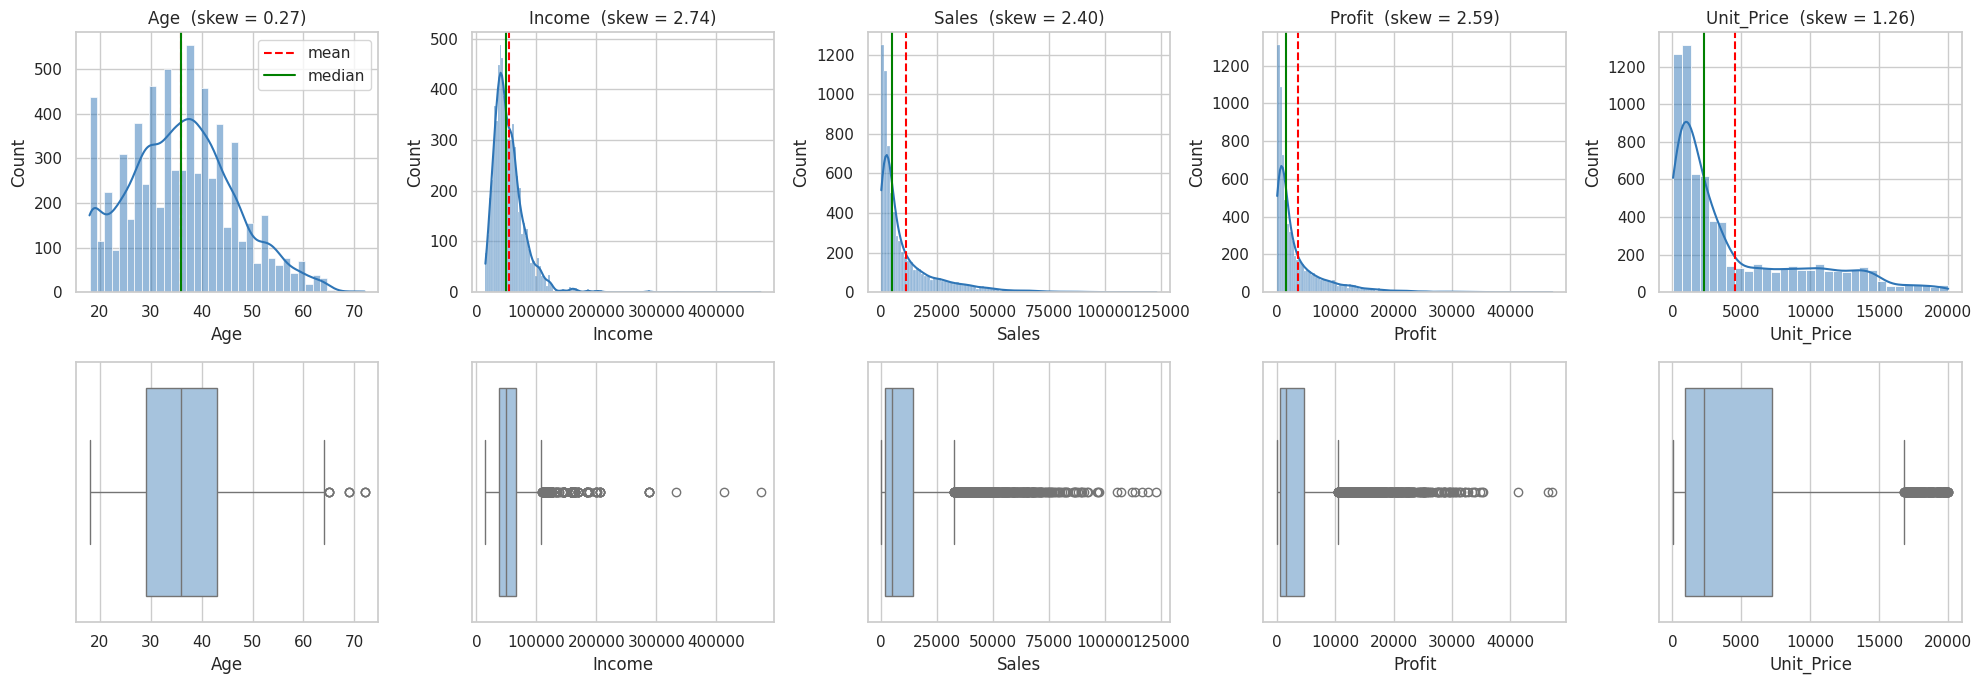

In [28]:
num_plot = ["Age", "Income", "Sales", "Profit", "Unit_Price"]
fig, axes = plt.subplots(2, len(num_plot), figsize=(20, 7))
for i, c in enumerate(num_plot):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color="#2E75B6")
    axes[0, i].axvline(df[c].mean(), color="red", ls="--", label="mean")
    axes[0, i].axvline(df[c].median(), color="green", ls="-", label="median")
    axes[0, i].set_title(f"{c}  (skew = {df[c].skew():.2f})")
    if i == 0: axes[0, i].legend()
    sns.boxplot(x=df[c], ax=axes[1, i], color="#9DC3E6")
plt.tight_layout()
plt.savefig("figs/distributions.png", dpi=130, bbox_inches="tight")
plt.show()

In [29]:
pd.DataFrame({"skew": df[["Age","Income","Quantity","Unit_Price","Discount","Sales","Cost","Profit"]].skew(),
              "mean": df[["Age","Income","Quantity","Unit_Price","Discount","Sales","Cost","Profit"]].mean(),
              "median": df[["Age","Income","Quantity","Unit_Price","Discount","Sales","Cost","Profit"]].median()})

,skew,mean,median
Age,0.27,36.05,36.00
Income,2.74,"54,406.56","48,816.07"
Quantity,0.73,3.01,3.00
Unit_Price,1.26,"4,519.23","2,261.47"
Discount,0.64,0.20,0.18
Sales,2.40,"10,961.60","4,825.56"
Cost,2.47,"7,371.90","3,229.89"
Profit,2.59,"3,589.70","1,528.70"


**Reading the shapes (business meaning).**
- **Age** is almost symmetric (skew near 0): mean and median are about the same, so the customer base is a balanced mix centred in the mid-30s.
- **Income** is clearly **right-skewed**: the mean sits above the median because a minority of high earners pull the average up. The median is the honest "typical customer" figure.
- **Sales** and **Profit** are strongly **right-skewed**: most transactions are small to medium, while a few large orders (high-priced electronics in bulk) are worth many times more. The average order value overstates what a normal order looks like.
- **Unit_Price** is also right-skewed because the catalogue mixes low-priced items (groceries, stationery) with high-priced ones (electronics).

### 4.3 Categorical variables: frequency and proportion

--- Region ---


,count,share_%
Region,,
West,1798,25.69
East,1765,25.21
South,1761,25.16
North,1676,23.94


--- Product_Category ---


,count,share_%
Product_Category,,
Electronics,1975,28.21
Grocery,1669,23.84
Clothing,1533,21.90
Furniture,979,13.99
Office Supplies,844,12.06


--- Customer_Segment ---


,count,share_%
Customer_Segment,,
Consumer,3840,54.86
Corporate,2114,30.20
Home Office,1046,14.94


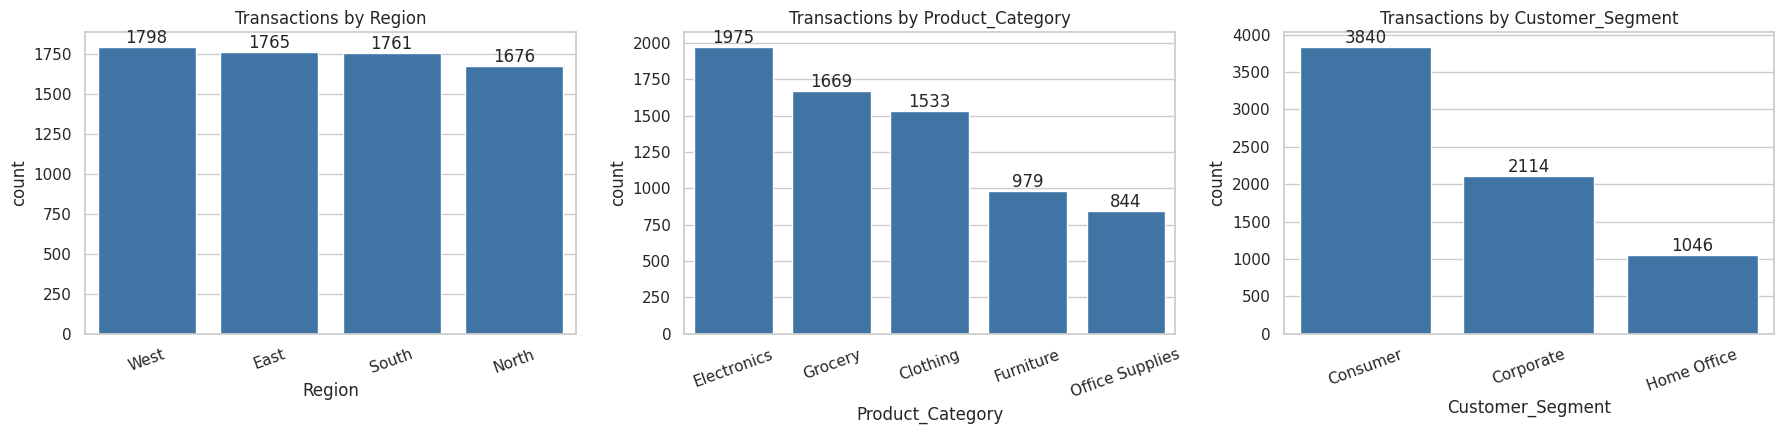

In [30]:
for c in ["Region", "Product_Category", "Customer_Segment"]:
    t = pd.DataFrame({"count": df[c].value_counts(), "share_%": df[c].value_counts(normalize=True) * 100})
    print(f"--- {c} ---"); display(t)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, ["Region", "Product_Category", "Customer_Segment"]):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax, color="#2E75B6")
    ax.set_title(f"Transactions by {c}"); ax.tick_params(axis="x", rotation=20)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig("figs/categorical.png", dpi=130, bbox_inches="tight"); plt.show()

Regions are fairly evenly balanced, categories are spread across five groups, and **Consumers are the largest segment by transaction count** (more than half), with Corporate and Home Office smaller.

## 5. Outlier detection

The IQR rule flags values below `Q1 - 1.5xIQR` or above `Q3 + 1.5xIQR`. The Z-score rule flags `|z| > 3`. We apply both, and compare **raw** vs **cleaned** Age and Income, because some outliers were data errors that cleaning already removed.

In [31]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    lo, hi = q1 - 1.5*i, q3 + 1.5*i
    return (s < lo) | (s > hi), lo, hi

rows = []
for name, s in [("Sales", df.Sales), ("Profit", df.Profit),
                ("Age (raw)", raw.Age.dropna()), ("Age (clean)", df.Age),
                ("Income (raw)", raw.Income.dropna()), ("Income (clean)", df.Income)]:
    m, lo, hi = iqr_outliers(s)
    z = ((s - s.mean()) / s.std()).abs() > 3
    rows.append([name, len(s), m.sum(), round(m.mean()*100, 2), round(lo, 1), round(hi, 1), z.sum()])
pd.DataFrame(rows, columns=["variable","n","IQR_outliers","IQR_%","lower_fence","upper_fence","Z>3_outliers"])

,variable,n,IQR_outliers,IQR_%,lower_fence,upper_fence,Z>3_outliers
0,Sales,7000,632,9.03,"-16,604.40","32,515.20",153
1,Profit,7000,640,9.14,"-5,364.70","10,472.10",160
2,Age (raw),6942,17,0.24,8.00,64.00,4
3,Age (clean),7000,10,0.14,8.00,64.00,6
4,Income (raw),6831,245,3.59,"-5,451.40","107,904.40",41
5,Income (clean),7000,231,3.30,"-5,756.30","108,594.80",80


### 5.1 Sales and Profit: who are the outliers?

In [32]:
m_sales, lo, hi = iqr_outliers(df.Sales)
out = df[m_sales]
print("High-sales outliers:", len(out), f"(fence = {hi:,.0f})")
display(out.Product_Category.value_counts().to_frame("outliers"))
display(out.groupby("Product_Category").agg(avg_qty=("Quantity","mean"), avg_unit_price=("Unit_Price","mean")))
print("Share of total revenue from these outliers: %.1f%%" % (out.Sales.sum() / df.Sales.sum() * 100))
print("Are they recorded consistently? Profit==Sales-Cost for all:", ((out.Profit-(out.Sales-out.Cost)).abs()<0.02).all())

High-sales outliers: 632 (fence = 32,515)


,outliers
Product_Category,
Electronics,332
Furniture,300


,avg_qty,avg_unit_price
Product_Category,,
Electronics,4.57,"12,138.46"
Furniture,4.18,"15,220.81"


Share of total revenue from these outliers: 39.6%
Are they recorded consistently? Profit==Sales-Cost for all: True


**Verdict: genuine extremes, keep them.** Sales outliers come almost entirely from high-priced categories bought in larger quantities, and their Sales/Cost/Profit are internally consistent. They are real big orders, not errors, and they contribute a disproportionate share of revenue. Removing them would delete the most valuable sales. Because of them we report **medians** alongside means.

### 5.2 Age and Income
- **Raw Age:** the six values (-12, -5, -1, 150, 180, 999) are **data errors**. No customer is negative or 999 years old. Already fixed in 3.5.
- **Raw Income:** six values over 500,000 were **data errors**: the same customers earn 10 times less in their other orders. Already fixed in 3.5b.
- **Clean Income:** the remaining IQR outliers (high earners, up to about Rs 4.7 lakh) are **genuine**: a right-skewed income distribution always has a long tail. Kept.

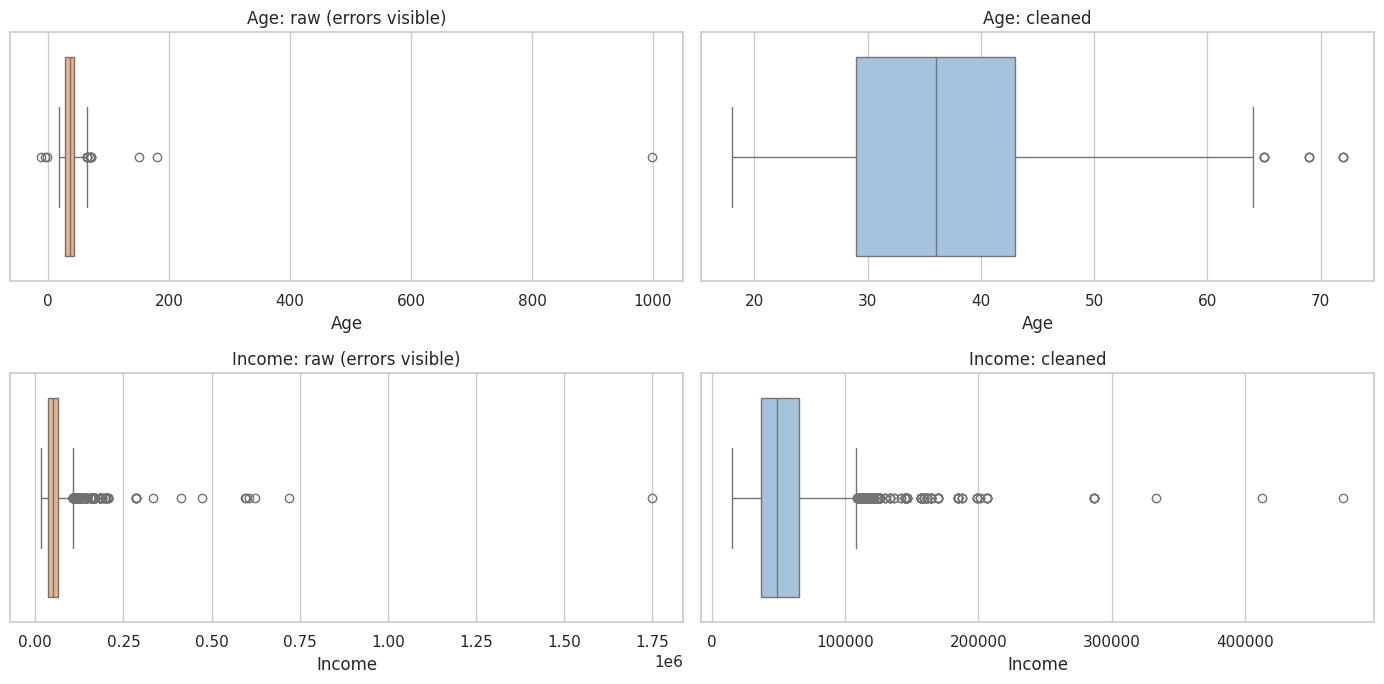

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
sns.boxplot(x=raw.Age, ax=axes[0,0], color="#F4B183");   axes[0,0].set_title("Age: raw (errors visible)")
sns.boxplot(x=df.Age, ax=axes[0,1], color="#9DC3E6");    axes[0,1].set_title("Age: cleaned")
sns.boxplot(x=raw.Income, ax=axes[1,0], color="#F4B183"); axes[1,0].set_title("Income: raw (errors visible)")
sns.boxplot(x=df.Income, ax=axes[1,1], color="#9DC3E6");  axes[1,1].set_title("Income: cleaned")
plt.tight_layout(); plt.savefig("figs/outliers_before_after.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Feature engineering and grouped business questions

### 6.1 Calculated columns

In [34]:
# 1. Profit margin: profit earned per rupee of sales
df["Profit_Margin"] = df.Profit / df.Sales

# 2. Delivery time in days (NaN where delivery date missing or flagged)
df["Delivery_Days"] = (df.Delivery_Date - df.Order_Date).dt.days

# 3. Revenue per customer: total lifetime sales of each customer, repeated on each row
df["Revenue_per_Customer"] = df.groupby("Customer_ID").Sales.transform("sum")

# 4. Order month and year for time analysis
df["Order_Year"]  = df.Order_Date.dt.year
df["Order_Month"] = df.Order_Date.dt.to_period("M").astype(str)

# 5. Age group
df["Age_Group"] = pd.cut(df.Age, bins=[17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])

# 6. Discount band
df["Discount_Band"] = pd.cut(df.Discount, bins=[-0.001, 0.10, 0.20, 0.30, 0.50],
                             labels=["0-10%", "10-20%", "20-30%", "30-50%"])

df[["Profit_Margin","Delivery_Days","Revenue_per_Customer","Order_Month","Age_Group","Discount_Band"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Profit_Margin,"7,000.00",NaN,NaN,NaN,0.33,0.07,0.20,0.26,0.33,0.39,0.45
Delivery_Days,"6,880.00",NaN,NaN,NaN,5.65,2.82,1.00,4.00,6.00,8.00,17.00
Revenue_per_Customer,"7,000.00",NaN,NaN,NaN,"58,627.35","41,938.58",157.81,"27,254.94","50,108.64","80,183.94","254,002.26"
Order_Month,7000,24,2024-03,321,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age_Group,7000,5,36-45,2335,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_Band,7000,4,10-20%,2329,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
df.to_csv("2026m01410006_Cleaned_Dataset.csv", index=False)   # re-save including the new columns
print("Final cleaned dataset:", df.shape)

Final cleaned dataset: (7000, 37)


### 6.2 Business questions (groupby and aggregation)

**Q1. Which region has the highest average order value, and which brings in the most revenue?**

In [36]:
q1 = df.groupby("Region").agg(orders=("Sales","count"), total_sales=("Sales","sum"),
                              avg_order_value=("Sales","mean"), median_order=("Sales","median"),
                              total_profit=("Profit","sum")).sort_values("total_sales", ascending=False)
q1

,orders,total_sales,avg_order_value,median_order,total_profit
Region,,,,,
East,1765,"20,018,192.35","11,341.75","5,029.99","6,607,664.00"
West,1798,"19,758,995.56","10,989.43","4,872.94","6,472,920.07"
South,1761,"18,890,109.55","10,726.92","4,747.23","6,177,763.05"
North,1676,"18,063,891.81","10,777.98","4,628.11","5,869,535.54"


**Implication.** East has the highest average order value (about Rs 11,342) and the highest total sales, while West has the most orders. But the gap between best and worst region is only around 5%. Regions are not a strong lever: no region needs rescuing, and growth effort is better aimed at *what* is sold than *where*.

**Q2. Which product category has the lowest (and highest) profit margin?**

In [37]:
q2 = df.groupby("Product_Category").agg(total_sales=("Sales","sum"), total_profit=("Profit","sum"),
                                         avg_margin=("Profit_Margin","mean")).sort_values("avg_margin")
q2["revenue_share_%"] = q2.total_sales / q2.total_sales.sum() * 100
q2["profit_share_%"]  = q2.total_profit / q2.total_profit.sum() * 100
q2

,total_sales,total_profit,avg_margin,revenue_share_%,profit_share_%
Product_Category,,,,,
Clothing,"7,781,680.39","2,521,027.84",0.32,10.14,10.03
Grocery,"2,685,875.10","874,840.19",0.32,3.50,3.48
Office Supplies,"2,566,182.51","832,190.36",0.33,3.34,3.31
Electronics,"37,639,557.39","12,352,219.50",0.33,49.05,49.16
Furniture,"26,057,893.88","8,547,604.77",0.33,33.96,34.02


**Implication.** Margins are almost identical across categories (32% to 33%), so Clothing and Grocery are not "low-margin" problems. The real story is **volume of value**: Electronics (49%) and Furniture (34%) generate about 83% of both revenue and profit, while Grocery and Office Supplies together are under 7%. Profit follows high-priced products, not better margins.

**Q3. Do bigger discounts reduce profit margin?**

In [38]:
q3 = df.groupby("Discount_Band").agg(orders=("Sales","count"), avg_margin=("Profit_Margin","mean"),
                                      avg_sales=("Sales","mean"), avg_qty=("Quantity","mean"))
q3

,orders,avg_margin,avg_sales,avg_qty
Discount_Band,,,,
0-10%,1668,0.33,"13,085.47",3.01
10-20%,2329,0.33,"11,541.64",3.00
20-30%,1679,0.33,"10,409.74",3.02
30-50%,1324,0.32,"7,965.40",3.00


**Implication.** Margin barely moves (33% to 32%) as discounts rise, but average order size *falls* (Rs 13,085 to Rs 7,965) and quantity does **not** rise. So deeper discounts are not buying bigger baskets: customers are simply paying less for the same quantity. This is worth testing before running more heavy discount campaigns.

**Q4. Which customer segment is the most valuable?**

In [39]:
q4 = df.groupby("Customer_Segment").agg(orders=("Sales","count"), total_sales=("Sales","sum"),
                                         avg_order_value=("Sales","mean"), total_profit=("Profit","sum"),
                                         avg_margin=("Profit_Margin","mean")).sort_values("total_sales", ascending=False)
q4["sales_share_%"] = q4.total_sales / q4.total_sales.sum() * 100
q4

,orders,total_sales,avg_order_value,total_profit,avg_margin,sales_share_%
Customer_Segment,,,,,,
Consumer,3840,"41,718,896.33","10,864.30","13,703,577.36",0.33,54.37
Corporate,2114,"23,551,202.48","11,140.59","7,665,257.93",0.32,30.69
Home Office,1046,"11,461,090.46","10,957.07","3,759,047.37",0.33,14.94


**Implication.** Consumers bring 54% of revenue simply by being the largest group. Corporate customers have the highest average order (about Rs 11,141) but only 30% of sales. Per order the three segments are nearly equal, so growth in segment value comes from **more orders**, not bigger ones.

**Q5. Which categories are returned most often?**

In [40]:
df["Returned_Flag"] = (df.Returned == "Yes").astype(int)
q5 = df.groupby("Product_Category").agg(orders=("Returned_Flag","count"), return_rate_pct=("Returned_Flag","mean")).sort_values("return_rate_pct", ascending=False)
q5["return_rate_pct"] *= 100
display(q5)
print("Overall return rate: %.1f%%" % (df.Returned_Flag.mean()*100))
print("Revenue on returned orders: Rs {:,.0f} ({:.1f}% of total sales)".format(df.loc[df.Returned_Flag==1,"Sales"].sum(), df.loc[df.Returned_Flag==1,"Sales"].sum()/df.Sales.sum()*100))

,orders,return_rate_pct
Product_Category,,
Clothing,1533,13.50
Furniture,979,13.18
Grocery,1669,12.46
Electronics,1975,12.10
Office Supplies,844,11.49


Overall return rate: 12.6%
Revenue on returned orders: Rs 9,037,761 (11.8% of total sales)


**Implication.** About 1 in 8 orders (12.6%) is returned, worth roughly Rs 9 million or 11.8% of sales. Return rates differ only slightly by category (11.5% to 13.5%), so the cause is probably not a specific product line.

**Q6. Does delivery mode affect delivery time and customer rating?**

In [41]:
q6 = df.groupby("Delivery_Mode").agg(avg_days=("Delivery_Days","mean"), avg_rating=("Customer_Rating","mean"),
                                      orders=("Sales","count"), return_rate=("Returned_Flag","mean"))
q6["return_rate"] *= 100
q6

,avg_days,avg_rating,orders,return_rate
Delivery_Mode,,,,
Express,5.63,3.11,2055,12.41
Same-Day,5.77,3.12,696,12.79
Standard,5.65,3.08,4249,12.61


**Implication.** Same-Day and Express orders take **no less time** than Standard (about 5.6 to 5.8 days each) and get no better ratings. If customers pay extra for faster modes, the promise is not being delivered. This is a clear operational check for the logistics team.

**Q7. How did sales trend over the two years?**

,sales,profit,orders
Order_Year,,,
2023,"38,655,639.29","12,509,509.31",3525
2024,"38,075,549.98","12,618,373.35",3475


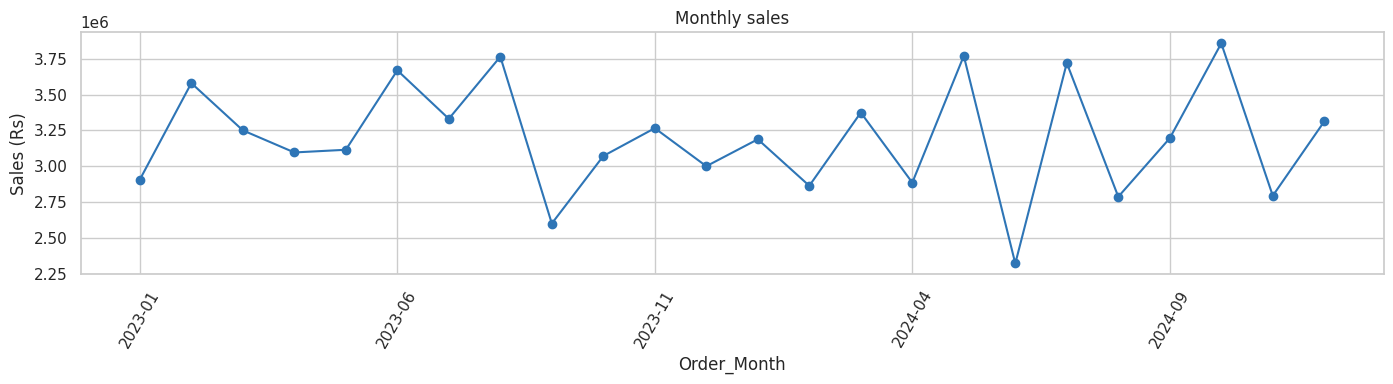

In [42]:
q7 = df.groupby("Order_Month").Sales.sum()
yearly = df.groupby("Order_Year").agg(sales=("Sales","sum"), profit=("Profit","sum"), orders=("Sales","count"))
display(yearly)
fig, ax = plt.subplots(figsize=(14, 4))
q7.plot(ax=ax, marker="o", color="#2E75B6"); ax.set_title("Monthly sales"); ax.set_ylabel("Sales (Rs)")
plt.xticks(rotation=60); plt.tight_layout(); plt.savefig("figs/monthly_sales.png", dpi=130, bbox_inches="tight"); plt.show()

**Implication.** Sales were essentially flat: about Rs 38.7M in 2023 vs Rs 38.1M in 2024 (-1.5%). Monthly sales bounce around Rs 2.3M to 3.9M with no consistent seasonal pattern, so the business is stable but not growing.

**Q8. Do customers who rate low also have higher return rates?**

In [43]:
q8 = df.groupby("Customer_Rating").agg(orders=("Sales","count"), return_rate=("Returned_Flag","mean"))
q8["return_rate"] *= 100
q8

,orders,return_rate
Customer_Rating,,
1.00,353,34.56
2.00,1475,37.56
3.00,2511,3.42
4.00,1693,2.78
5.00,548,3.28


**Implication (strongest finding).** Orders rated **1 or 2 stars are returned 35% to 38% of the time**, versus only about 3% for ratings of 3 to 5. A low rating is therefore an early warning that a return is happening or has happened. Satisfaction shows the same pattern: Low-satisfaction orders are returned 27% of the time, High only 4%. Following up quickly on 1 to 2 star ratings could save sales.

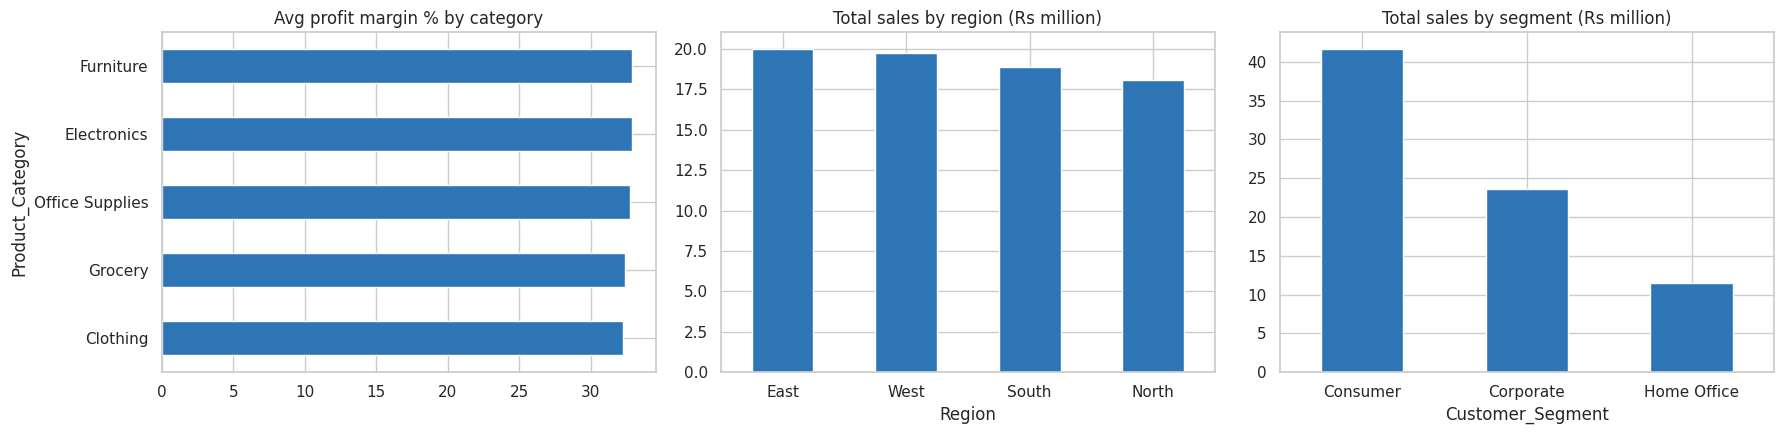

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
q2["avg_margin"].mul(100).sort_values().plot.barh(ax=axes[0], color="#2E75B6"); axes[0].set_title("Avg profit margin % by category")
q1["total_sales"].div(1e6).plot.bar(ax=axes[1], color="#2E75B6"); axes[1].set_title("Total sales by region (Rs million)")
q4["total_sales"].div(1e6).plot.bar(ax=axes[2], color="#2E75B6"); axes[2].set_title("Total sales by segment (Rs million)")
for a in axes: a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("figs/business_summary.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Key findings and implications
1. **Two categories drive the business.** Electronics and Furniture make up about 83% of revenue and profit; Grocery and Office Supplies add under 7%.
2. **Averages are misleading.** Sales are strongly right-skewed (skew 2.4): the typical order is about Rs 4,800 but the mean is about Rs 11,000. Big orders (9% of orders) bring about 40% of revenue.
3. **Low ratings predict returns.** 1 to 2 star orders are returned 35% to 38% of the time vs about 3% for 3 to 5 stars.
4. **Faster delivery is not faster.** Same-Day and Express take as long as Standard (about 5.7 days).
5. **Discounts do not increase basket size.** Higher discounts lower the average order without raising quantity.
6. **Margins are uniform (about 33%)**, so profit depends on selling high-value items, not on category pricing.
7. **Sales are flat year over year** (-1.5%) with no clear seasonality, and regions and segments differ by only a few percent per order.

**Data quality note.** 84 duplicate records, ~320 dates in mixed formats, 12 impossible Age/Income values, 6 invalid Discounts and 15 delivery-before-order rows were found and handled. See Section 3 for each decision.

**Deliverables:** `2026m01410006_Cleaned_Dataset.csv` and the charts in `figs/`.